__Tasks:__
- [x] Collect a MVD (Minimum Viable Data)
    - I'm using the raw data for MOLM-13 screen from this [bioRxiv](https://www.biorxiv.org/content/10.1101/2022.12.14.518457v1)
- [x] Trim reads in FASTQ, count unique sequences, and map to V2 sgRNA library table.
- [ ] Compare with ScreenProcessing

# Collect data
A Minimum Viable Data (MVD)!

In [1]:
# import subprocess 

In [2]:
# %%bash 
# mkdir -p molm13_exp_fastq/

# for fq in `gsutil ls gs://crispr-screens/genome-scale-pooled-v2/molm13_exp`; do
#     b=`basename $fq`;
#     gsutil cp $fq molm13_exp_fastq/$b;
# done

In [2]:
def oligo_sequence_design():
    """
    """
    ## assuming R1=19, R2=19
    r1 = 'G'+19*'N'
    r2 = 19*'N'
    # r1 = 'G'+19*'N'
    print(f'oligo: {len(r1)*"A"}{len(r2)*"B"}')
    print(f'read1: {r1}{len(r2)*"-"}, length: {len(r1)}')
    print(f'read2: {len(r1)*"-"}{r2}, length: {len(r1)}')
    print()    
    print('A: protospacer A')
    print('B: protospacer B')


In [3]:
oligo_sequence_design()

oligo: AAAAAAAAAAAAAAAAAAAABBBBBBBBBBBBBBBBBBB
read1: GNNNNNNNNNNNNNNNNNNN-------------------, length: 20
read2: --------------------NNNNNNNNNNNNNNNNNNN, length: 20

A: protospacer A
B: protospacer B


# Count FASTQ ...

In [4]:
import matplotlib.pyplot as plt

In [5]:
import sys

sys.path.append('../../../ScreenPro2/')

from screenpro import ngs

In [6]:
import pandas as pd

In [7]:
import anndata as ad

import polars as pl

from time import time

from glob import glob

In [8]:
from pyfaidx import Fasta

### 

### 

In [9]:
# !wget https://raw.githubusercontent.com/mhorlbeck/ScreenProcessing/master/library_reference/CRISPRi_v2_human.trim_1_29_forward.fa

# !mkdir -p ../../../ScreenPro2/library_reference
# !mv CRISPRi_v2_human.trim_1_29_forward.fa \
#     ../../../ScreenPro2/library_reference/CRISPRi_v2_human.trim_1_29_forward.fasta

In [10]:
fasta_file_path = '../../../ScreenPro2/library_reference/CRISPRi_v2_human.trim_1_29_forward.fasta'

In [11]:
import biobear as bb

In [12]:
!cat {fasta_file_path} | wc -l

418140


In [13]:
library = bb.FastaReader(fasta_file_path)

In [14]:
library.to_pandas()

,id,description,sequence
0,A1BG_-_58858617.23-P1,None,GAGACCCAGCGCTAACCAGGTTTAAGAG
1,A1BG_-_58858788.23-P1,None,GGGCACCCAGGAGCGGTAGGTTTAAGAG
2,A1BG_+_58858964.23-P1,None,CTCCGGGCGACGTGGAGTGGTTTAAGAG
3,A1BG_-_58858630.23-P1,None,AACCAGGGGTGCCCAAGGGGTTTAAGAG
4,A1BG_+_58858549.23-P1,None,GCGAGGAACCGCCCAGCAAGTTTAAGAG
...,...,...,...
209065,non-targeting_03785,None,CTACTCCGCCCCGCGGGAGGTTTAAGAG
209066,non-targeting_03786,None,TGGCCGTTCATGGGACCGGGTTTAAGAG
209067,non-targeting_03787,None,AACTCTGTAGAAGGGACCGGTTTAAGAG
209068,non-targeting_03788,None,CTCGACAGCGACTGAAGAGGTTTAAGAG


In [15]:
# library_fa = Fasta(fasta_file_path)

In [16]:
# pd.DataFrame([ (sgId, str(seq)) for sgId, seq in library_fa.items()],columns=['sgId','sequence'])

In [17]:
# library_fa.keys()

In [18]:
# library = pd.DataFrame(library_fa.items())

In [19]:
# library

In [20]:
library = pd.read_csv('../../../ScreenPro2/library_tables/CRISPRi_v2_human_librarytable.txt.gz',sep='\t')
library.sequence = library.sequence.str.upper().str[1:]

library_full = library.copy()

library = library.drop_duplicates('sequence',keep='first').set_index('sequence')

### Get Counts

Note: `Upper` helped to increase the mapping efficiency!

In [21]:
counts = {}

for fq_file in glob('molm13_exp_fastq/*'):
    sample_id = fq_file.split('/')[1].split('.')[0]
    
    print(f"\033[1m{sample_id}\033[0m")
    
    df_cnt = ngs.fastq_to_count_unique_seq(fq_file,slice_seq=(1,19)).to_pandas()
    count_df = ngs.map_sample_counts_to_library(library,df_cnt)
    
    counts[sample_id] = count_df

DMSO_Rep2
load FASTQ file as a Polars DataFrame



KeyboardInterrupt



### Make `AnnData`

In [ ]:
counts_df = pd.concat(dict([(name,df['counts']) for name, df in counts.items()]),axis=1)

In [ ]:
adata = ad.AnnData(X=counts_df.T,var=library)

adata = adata[:,adata.to_df().sum().gt(0)].copy()

### Compare counts with ScreenProcessing

In [ ]:
# !wget 'https://raw.githubusercontent.com/GilbertLabUCSF/Decitabine-treatment/main/DAC/CRISPRi-screen/molm13_exp/mergedcountstable.txt'

In [22]:
screenprocessing_counts = pd.read_csv(
    'mergedcountstable.txt', 
    sep='\t', 
    header=list(range(2)),
    index_col=list(range(1))
)

screenprocessing_counts = screenprocessing_counts[screenprocessing_counts.sum(axis=1).gt(0)]

In [ ]:
from venn import venn

In [ ]:
library

In [ ]:
fig,(ax,bx) = plt.subplots(1,2,figsize=(12,6))
venn({
    'library_table':set(library_full.sgId),
    'ScreenPro2':set(adata.var.sgId),
    'ScreenProcessing':set(screenprocessing_counts.index)#.loc[adata.var.sgId,:]
},legend_loc=None,ax=ax)
ax.set_title('mapped_sg_Ids',fontsize=16)

venn({
    'library_table':set(library_full.sequence),
    'ScreenPro2':set(adata.var.index),
    'ScreenProcessing':set(library_full.set_index('sgId').loc[screenprocessing_counts.index,'sequence'].to_list())
},legend_loc='best',ax=bx)
bx.set_title('mapped_sg_sequences',fontsize=16)
plt.show()

In [ ]:
# set(adata.var.sgId) - set(screenprocessing_counts.index)#.loc[adata.var.sgId,:]

In [ ]:
tmp1 = set(library_full.set_index('sgId').loc[screenprocessing_counts.index,'sequence'].to_list()) - set(adata.var.index)

In [ ]:
sorted_tmp = adata[:,list(set(adata.var.index) - set(library_full.set_index('sgId').loc[screenprocessing_counts.index,'sequence'].to_list()))].to_df().sum().sort_values().index

In [ ]:
fq_file

In [27]:
fq2fa_file = fq_file.replace('fastq.gz','fasta.gz')

In [ ]:
!seqkit fq2fa -j 6 {fq_file} -o {fq2fa_file}

In [ ]:
df_fq = ngs.fastq_to_dataframe(
    fq_file,
    engine='biobear'
)

load FASTQ file as a Polars DataFrame


In [ ]:
ls

In [118]:
!zcat {fq_file} | wc -l 

378905956


In [119]:
378905956 / 4

94726489.0

In [ ]:
df_fq = bb.FastqReader(fq_file,compression=Compression.GZIP).to_polars()

In [120]:
df_fq.shape

(6570617, 4)

In [103]:
screenprocessing_counts['T0']['Rep2'].sum() / 89965203

0.9513100192748968

In [104]:
adata.to_df().loc['T0_Rep2'].sum() / 89965203

0.06572690109975075

<AxesSubplot: >

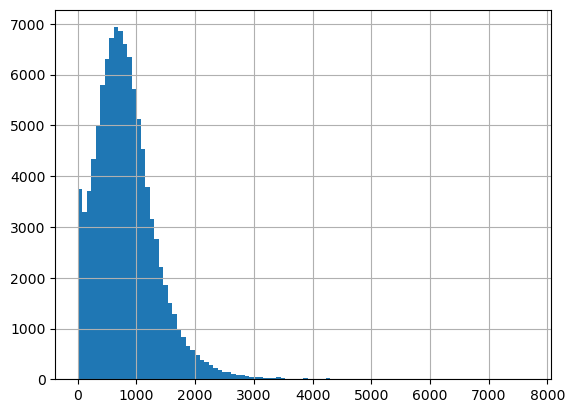

In [102]:
screenprocessing_counts['T0']['Rep2'].hist(bins=100)

<AxesSubplot: >

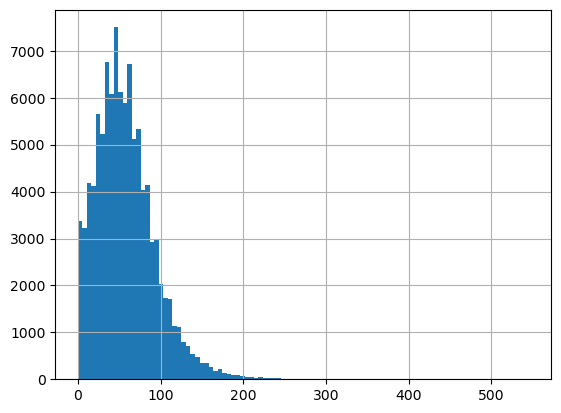

In [105]:
adata.to_df().loc['T0_Rep2'].hist(bins=100)

In [ ]:
# adata.var.sgId.to_list()

In [ ]:
# screenprocessing_counts#.loc[adata.var.sgId,:]

In [66]:
def plot_count_benchmark():
    pass
    #screen, growth_factor_table, score, cond1, cond2, get_z_score, title):
#     screenprocessing_results = screen.phenotypes['phenotypetable'][score]

#     screenpro2_results = scp.ps.runPhenoScoreForReplicate(
#         screen,cond1,cond2,
#         score,
#         growth_factor_table,
#         get_z_score=get_z_score
#     ).loc[screenprocessing_results.index,:]#.add_prefix('hl60_gamma_')

#     fig, ax = plt.subplots(figsize=(3.7,3.7))

#     ax.scatter(
#         x=screenprocessing_results['Rep1'],
#         y=screenpro2_results['replicate_1'],
#         facecolors='#3182bd',
#         s=3,c=almost_black
#     )
#     ax.set_xlabel('ScreenProcessing')
#     ax.set_ylabel('ScreenPro2\nscore')

#     ax.axline((0, 0), slope=1)

#     # ax.set_xlim(-3.5,3.5)
#     # ax.set_ylim(-3.5,3.5)

#     fig.suptitle(title,fontsize=12)

#     # plt.savefig('NAC_counts_qc.pdf',bbox_inches='tight')
#     # plt.tight_layout()
#     plt.show()

In [68]:
plot_count_benchmark()

# 